# D5: Pruning a wine-classification tree
**Student:** Chiranthan D R  |  **Reg. ID:** GF202568204  |  **Course:** Statistics for Data Science

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

data = load_wine()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=3, stratify=y)
print("Train size:", len(X_train), "Test size:", len(X_test))



Train size: 124 Test size: 54


## 1. Fully grown tree

In [ ]:
full = DecisionTreeClassifier(random_state=3).fit(X_train, y_train)
full_leaves, full_depth = full.get_n_leaves(), full.get_depth()
full_acc = full.score(X_test, y_test)
print(f"Full tree -> leaves: {full_leaves}, depth: {full_depth}, test acc: {full_acc:.4f}")



Full tree -> leaves: 11, depth: 6, test acc: 0.8889


## 2. Cost-complexity pruning path and 5-fold CV

In [ ]:
alphas = full.cost_complexity_pruning_path(X_train, y_train).ccp_alphas
print("Number of alphas:", len(alphas))
cv_acc, n_leaves = [], []
for a in alphas:
    clf = DecisionTreeClassifier(random_state=3, ccp_alpha=a)
    cv_acc.append(cross_val_score(clf, X_train, y_train, cv=5).mean())
    n_leaves.append(clf.fit(X_train, y_train).get_n_leaves())
cv_acc = np.array(cv_acc)
for a,c,l in zip(alphas,cv_acc,n_leaves):
    print(f"alpha={a:.6f}  cv_acc={c:.4f}  leaves={l}")



Number of alphas: 10
alpha=0.000000  cv_acc=0.8790  leaves=11
alpha=0.007889  cv_acc=0.8790  leaves=9
alpha=0.012097  cv_acc=0.8540  leaves=8
alpha=0.015450  cv_acc=0.8540  leaves=7
alpha=0.015553  cv_acc=0.8540  leaves=6
alpha=0.030678  cv_acc=0.8460  leaves=5
alpha=0.030722  cv_acc=0.8460  leaves=4
alpha=0.043113  cv_acc=0.8133  leaves=3
alpha=0.223836  cv_acc=0.7653  leaves=2
alpha=0.270030  cv_acc=0.4767  leaves=1


## 3. CV accuracy and number of leaves vs ccp_alpha

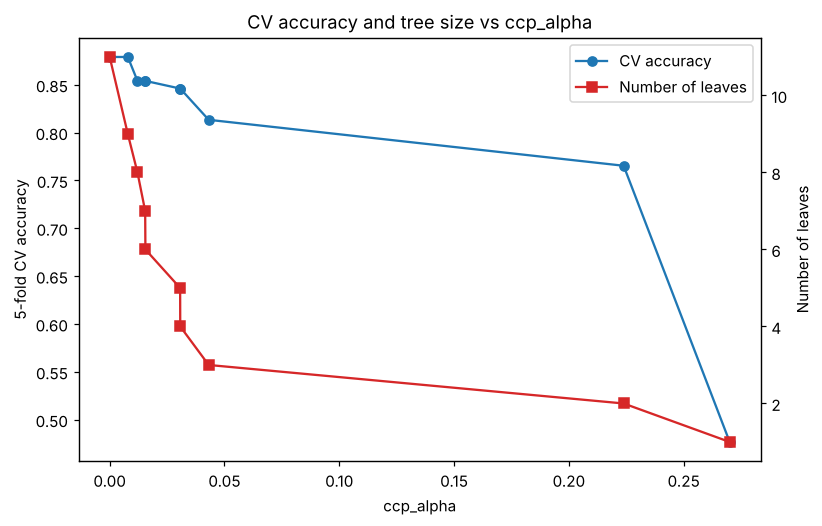

In [ ]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(alphas, cv_acc, marker="o", color="tab:blue", label="CV accuracy")
ax1.set_xlabel("ccp_alpha"); ax1.set_ylabel("5-fold CV accuracy")
ax2 = ax1.twinx()
ax2.plot(alphas, n_leaves, marker="s", color="tab:red", label="Number of leaves")
ax2.set_ylabel("Number of leaves")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="best")
plt.title("CV accuracy and tree size vs ccp_alpha")
plt.show()



## 4. Refit with best alpha

In [ ]:
best_idx = np.where(np.isclose(cv_acc, cv_acc.max()))[0][-1]
best_alpha = alphas[

Best alpha: 0.007889, CV acc: 0.8790
Pruned tree -> leaves: 9, depth: 4, test acc: 0.8889
Leaves reduced by: 2 (18.2%)
Test accuracy change: +0.0000


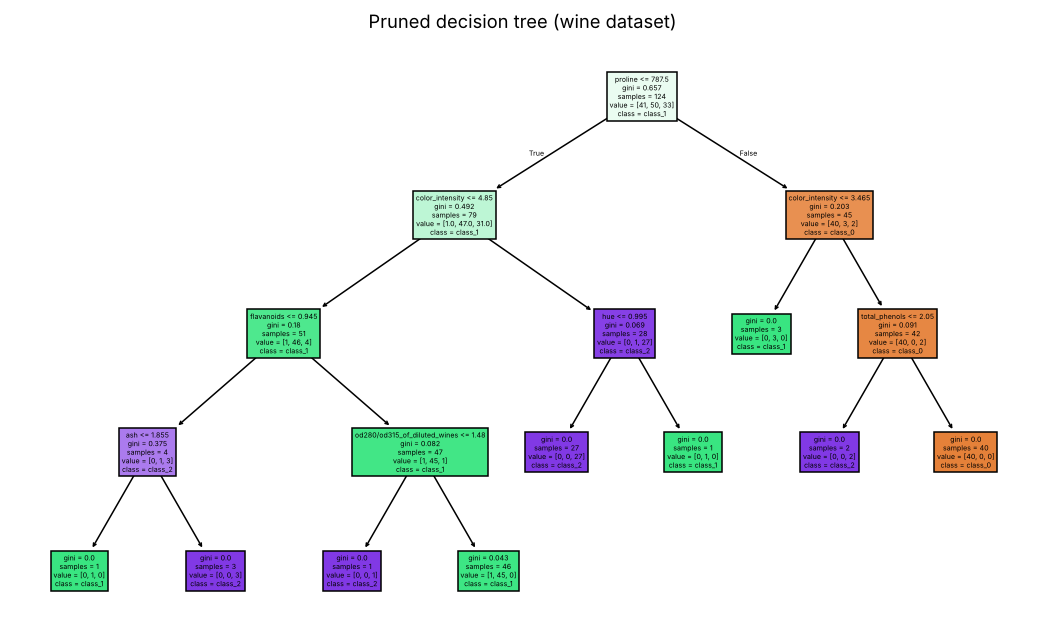

In [ ]:
plt.figure(figsize=(12, 7))
plot_tree(pruned, feature_names=data.feature_names, class_names=data.target_names, filled=True)
plt.title("Pruned decision tree (wine dataset)")
plt.show()


## Follow-up Q1: Reduction in leaves and effect on test accuracy
Pruning reduced the number of leaves from **11 to 9**, a reduction of **2 leaves (18.2%)**. Depth fell from **6 to 4**. Test accuracy stayed exactly the same at **0.8889** (48/54 correct) for both trees, a change of **+0.0000**. The best alpha was **0.007889**, with CV accuracy **0.8790**, the same as the unpruned tree's CV accuracy (alpha = 0). So pruning made the tree simpler at no cost in accuracy.

## Follow-up Q2: Why a smaller, slightly less accurate tree can be better for the lab
**Overfitting:** a fully grown tree keeps splitting until every training sample is classified correctly, so it fits noise in only 124 training rows. Its leaves can hold very few samples, and such splits often do not generalise. The CV curve shows accuracy falling as alpha rises (0.8790 at 9 leaves down to 0.4767 at 1 leaf), so there is a sweet spot; pruning removes the weakest branches that add complexity without improving cross-validated accuracy.

**Interpretability:** the lab needs a classifier small enough to print on one page. A tree with fewer leaves and lower depth (4 here, versus 6) gives shorter rules that technicians can follow by hand and check. If a much smaller tree loses only a little accuracy, it is the better choice because it is easier to read, less likely to overfit and more trustworthy. In our run the pruned tree lost no test accuracy at all, which makes it the clear choice.